# 10 祝日・天候・割引施策の条件付き集計

売上との関連を調べるため、店舗・年・月・曜日を揃え、比較対象があるグループだけを集計する。単純な全体平均より比較条件は近づくが、客層・気温・施策・連休などが違うため、**因果効果ではない**。

天候実績は2022〜2024年の記述分析にのみ使う。2025年に利用可能なのは平年値であり、観測天候を2025年の特徴量に使わない。

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'input').is_dir(): ROOT=ROOT.parent
assert (ROOT/'input').is_dir()
INPUT=ROOT/'input';sns.set_theme(style='whitegrid');pd.options.display.float_format='{:,.3f}'.format
train=pd.read_csv(INPUT/'train.csv',parse_dates=['date'])
menus=pd.read_csv(INPUT/'menus.csv')[['item_id','category']]
stores=pd.read_csv(INPUT/'stores.csv')[['store_id','area_type']]
calendar=pd.read_csv(INPUT/'calendar.csv',parse_dates=['date'])
campaign=pd.read_csv(INPUT/'campaign_calendar.csv',parse_dates=['date'])
train=train.merge(menus,on='item_id',validate='many_to_one')
daily=train.groupby(['date','store_id'],as_index=False).sales_amount.sum().merge(calendar,on='date',validate='many_to_one').merge(stores,on='store_id',validate='many_to_one')
daily['year']=daily.date.dt.year;daily['month']=daily.date.dt.month;daily['weekday']=daily.date.dt.dayofweek
print('store-days:',len(daily),'unique:',not daily.duplicated(['date','store_id']).any())

store-days: 10960 unique: True


## 店舗・年・月・曜日内の晴れ日と雨日
同じ条件に晴れ日と雨日が両方ある場合のみ比較する。各グループの雨日数を重みとして差を平均する。2025年の天候を予測した値ではない。

比較可能な店舗・年・月・曜日の組: 1740 対応する雨日店舗数: 2940 晴れ日店舗数: 3290
雨日数で重み付けした、雨日−晴日の平均差（円/店舗日）: -25729.41201814059


,matched_strata,rainy_store_days,weighted_difference
area_type,,,
office,348.000,588.000,"-7,008.360"
residential,348.000,588.000,"-40,677.277"
roadside,348.000,588.000,"-43,539.541"
suburban_sc,348.000,588.000,"-25,358.392"
urban_core,348.000,588.000,"-12,063.490"


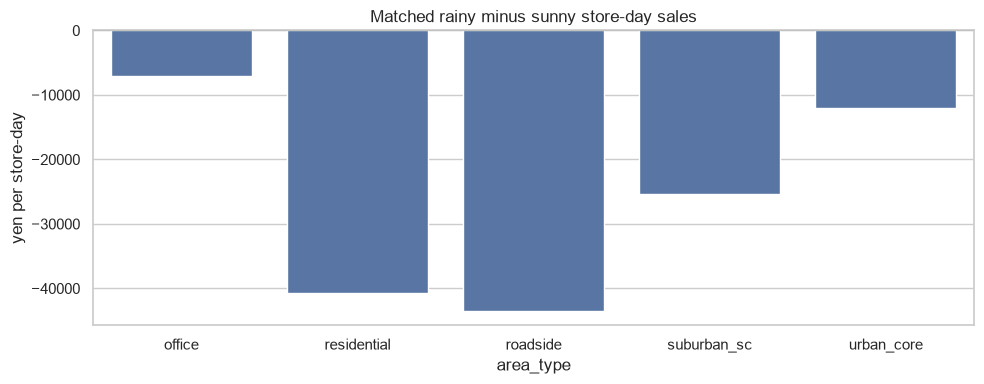

In [2]:
weather=daily[daily.weather_observed.isin(['sunny','rainy'])].copy()
strata=['store_id','year','month','weekday']
w=weather.groupby(strata+['weather_observed'],observed=True).sales_amount.agg(['mean','size']).unstack('weather_observed')
w=w.dropna(subset=[('mean','sunny'),('mean','rainy')]).copy()
w['difference']=w[('mean','rainy')]-w[('mean','sunny')];w['rainy_count']=w[('size','rainy')];w['sunny_count']=w[('size','sunny')]
weather_result=w.reset_index();weather_result.columns=['_'.join(c).strip('_') if isinstance(c,tuple) else c for c in weather_result.columns]
weather_result=weather_result.merge(stores,on='store_id',validate='many_to_one')
print('比較可能な店舗・年・月・曜日の組:',len(w),'対応する雨日店舗数:',int(w.rainy_count.sum()),'晴れ日店舗数:',int(w.sunny_count.sum()))
print('雨日数で重み付けした、雨日−晴日の平均差（円/店舗日）:',float(np.average(w.difference,weights=w.rainy_count)))
wr=weather_result.groupby('area_type').apply(lambda x:pd.Series({'matched_strata':len(x),'rainy_store_days':x.rainy_count.sum(),'weighted_difference':np.average(x.difference,weights=x.rainy_count)}),include_groups=False)
display(wr)
fig,ax=plt.subplots(figsize=(10,4));sns.barplot(data=wr.reset_index(),x='area_type',y='weighted_difference',ax=ax);ax.axhline(0,color='gray');ax.set(title='Matched rainy minus sunny store-day sales',ylabel='yen per store-day');plt.tight_layout();plt.show()

## 祝日の条件付き比較
祝日と非祝日の両方が同一店舗・年・月・曜日に存在する場合のみ。連休・季節・施策や観測天候の違いが残る。

In [3]:
h=daily.groupby(strata+['is_holiday'],observed=True).sales_amount.agg(['mean','size']).unstack('is_holiday')
h=h.dropna(subset=[('mean',False),('mean',True)]).copy()
h['difference']=h[('mean',True)]-h[('mean',False)];h['holiday_count']=h[('size',True)]
print('比較可能な組:',len(h),'祝日の店舗日:',int(h.holiday_count.sum()))
print('祝日店舗日で重み付けした、祝日−非祝日の平均差（円/店舗日）:',float(np.average(h.difference,weights=h.holiday_count)))
hr=h.reset_index();hr.columns=['_'.join(str(v) for v in c if v!='') if isinstance(c,tuple) else c for c in hr.columns]
hr=hr.merge(stores,on='store_id',validate='many_to_one')
display(hr.groupby('area_type').apply(lambda x:pd.Series({'matched_strata':len(x),'holiday_store_days':x.holiday_count.sum(),'weighted_difference':np.average(x.difference,weights=x.holiday_count)}),include_groups=False))

比較可能な組: 510 祝日の店舗日: 540
祝日店舗日で重み付けした、祝日−非祝日の平均差（円/店舗日）: 75985.29305555555


,matched_strata,holiday_store_days,weighted_difference
area_type,,,
office,102.000,108.000,"-108,255.674"
residential,102.000,108.000,"176,681.965"
roadside,102.000,108.000,"160,361.483"
suburban_sc,102.000,108.000,"61,449.728"
urban_core,102.000,108.000,"89,688.963"


## 対象カテゴリ別・割引施策予定日の比較
対象店舗と対象カテゴリを展開。対象カテゴリで**割引施策が何もない日**を対照とし、店舗・年・月・曜日・カテゴリ内で両方がある層に限って比較する。複数施策の重複や顧客選択は残り、これは実際のクーポン利用率でも因果効果でもない。

In [4]:
category_daily=train.groupby(['date','store_id','category'],as_index=False).sales_amount.sum()
coupon=campaign[campaign.coupon_flag].copy(); store_ids=stores.store_id.tolist()
coupon['store_id']=coupon.store_ids.map(lambda x:store_ids if x=='all' else x.split('|'));coupon=coupon.explode('store_id',ignore_index=True)
coupon_keys=(coupon[['date','store_id','target_item_group']].rename(columns={'target_item_group':'category'}).drop_duplicates().assign(planned=True))
category_daily=(category_daily.merge(coupon_keys,on=['date','store_id','category'],how='left',validate='one_to_one')
                .merge(calendar[['date','is_holiday']],on='date',validate='many_to_one'))
category_daily['planned']=category_daily.planned.fillna(False).astype(bool)
category_daily['year']=category_daily.date.dt.year;category_daily['month']=category_daily.date.dt.month;category_daily['weekday']=category_daily.date.dt.dayofweek
print('対象外カテゴリは予定日が存在しない:',category_daily.groupby('category').planned.sum().to_dict())
cstrata=['store_id','year','month','weekday','category']
c=category_daily.groupby(cstrata+['planned'],observed=True).sales_amount.agg(['mean','size']).unstack('planned')
c=c.dropna(subset=[('mean',False),('mean',True)]).copy()
c['difference']=c[('mean',True)]-c[('mean',False)];c['treated_count']=c[('size',True)]
cr=c.reset_index();cr.columns=['_'.join(str(v) for v in col if v!='') if isinstance(col,tuple) else col for col in cr.columns]
summary=cr.groupby('category').apply(lambda x:pd.Series({'matched_strata':len(x),'treated_store_days':x.treated_count.sum(),'weighted_difference_yen':np.average(x.difference,weights=x.treated_count),'treated_mean_yen':np.average(x['mean_True'],weights=x.treated_count),'control_mean_yen':np.average(x['mean_False'],weights=x.treated_count)}),include_groups=False)
summary['relative_difference']=summary.weighted_difference_yen/summary.control_mean_yen
display(summary)
print('各値は対象店舗・曜日などで集計した観察上の差。施策参加や日付はランダムに決まっていない。')

対象外カテゴリは予定日が存在しない: {'dessert': 2096, 'drink_bar': 0, 'kids': 444, 'lunch': 341, 'main': 355, 'side': 0}
各値は対象店舗・曜日などで集計した観察上の差。施策参加や日付はランダムに決まっていない。


,matched_strata,treated_store_days,weighted_difference_yen,treated_mean_yen,control_mean_yen,relative_difference
category,,,,,,
dessert,829.000,"1,187.000","6,062.391","35,163.055","29,100.664",0.208
kids,367.000,444.000,"4,599.450","32,616.768","28,017.318",0.164
lunch,238.000,341.000,"5,713.550","87,990.334","82,276.784",0.069
main,237.000,351.000,"3,757.038","407,235.350","403,478.312",0.009


## 解釈
- 上記の値は比較条件が揃った層に限定され、全店舗・全日の平均とは異なる。
- 天気や施策は季節、祝日、顧客層、同時施策などと相関する。比較対象が少ない層もあるため、関連を原因とは断定しない。
- 時系列検証で特徴量の有効性を確かめる。検証時にも利用可能時点に合わせ、天候実績や当日ログを未来の説明変数に使わない。